### Name: Mithun Kumar Rajak
### JLU ID: JLU08355
### Roll No. : 2023BTCSE010
### Program: B.Tech.(CSE)
### Course: Soft Computing (EL1)
### Course Code: STEL3101


## Module 3: Evolutionary Computation and Swarm Intelligence

This notebook demonstrates the main representation, evaluation, and optimization operations used in Genetic Algorithms (GA), Particle Swarm Optimization (PSO), and Differential Evolution (DE).

### Question 1:

To create and represent a population of individuals using binary, integer, and real-valued encoding methods in Python.

In [11]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
population_size = 6
gene_count = 5

binary_population = rng.integers(0, 2, size=(population_size, gene_count))
integer_population = rng.integers(0, 10, size=(population_size, gene_count))
real_population = rng.uniform(-5, 5, size=(population_size, gene_count))

print("Binary encoding:\n", binary_population)
print("\nInteger encoding:\n", integer_population)
print("\nReal-valued encoding:\n", np.round(real_population, 3))

Binary encoding:
 [[0 1 1 0 0]
 [1 0 1 0 0]
 [1 1 1 1 1]
 [1 1 0 1 0]
 [1 0 0 1 1]
 [1 0 1 1 0]]

Integer encoding:
 [[4 2 0 5 8]
 [0 8 8 2 6]
 [1 7 7 3 0]
 [9 4 8 6 7]
 [7 1 3 4 4]
 [0 5 1 7 6]]

Real-valued encoding:
 [[ 2.448  4.675 -1.742 -1.295 -0.304]
 [-3.105 -3.701 -0.243 -2.731  1.698]
 [-0.628  3.327  2.003 -1.876  3.323]
 [ 3.048 -1.125 -2.117  1.825 -3.602]
 [-3.001 -4.926  2.869  1.649  2.052]
 [ 2.807 -0.411  0.687 -3.602 -3.855]]


---
### Question 2:

To define and calculate a simple fitness function for evaluating individuals in a Genetic Algorithm using Python.

In [12]:
# Maximize the sum of the genes.
def fitness(individual):
    return float(np.sum(individual))

scores = np.array([fitness(individual) for individual in binary_population])
for number, (individual, score) in enumerate(zip(binary_population, scores), start=1):
    print(f"Individual {number}: {individual}, fitness={score:.0f}")
print(f"Best fitness: {scores.max():.0f}")

Individual 1: [0 1 1 0 0], fitness=2
Individual 2: [1 0 1 0 0], fitness=2
Individual 3: [1 1 1 1 1], fitness=5
Individual 4: [1 1 0 1 0], fitness=3
Individual 5: [1 0 0 1 1], fitness=3
Individual 6: [1 0 1 1 0], fitness=3
Best fitness: 5


---
### Question 3:

To implement basic selection methods for selecting suitable individuals from a population using Python.

In [13]:
def tournament_selection(population, scores, tournament_size=3):
    candidates = rng.choice(len(population), size=tournament_size, replace=False)
    return population[candidates[np.argmax(scores[candidates])]].copy()

def roulette_selection(population, scores):
    probabilities = (scores + 1) / (scores.sum() + len(scores))
    return population[rng.choice(len(population), p=probabilities)].copy()

selected_tournament = [tournament_selection(binary_population, scores) for _ in range(3)]
selected_roulette = [roulette_selection(binary_population, scores) for _ in range(3)]
print("Tournament selection:\n", np.array(selected_tournament))
print("\nRoulette-wheel selection:\n", np.array(selected_roulette))

Tournament selection:
 [[1 0 1 1 0]
 [1 1 1 1 1]
 [1 1 1 1 1]]

Roulette-wheel selection:
 [[0 1 1 0 0]
 [1 1 1 1 1]
 [1 0 1 0 0]]


---
### Question 4:

To implement the crossover operation for generating new offspring from selected individuals using Python.

In [14]:
def single_point_crossover(parent_one, parent_two, point=None):
    if point is None:
        point = rng.integers(1, len(parent_one))
    child_one = np.concatenate((parent_one[:point], parent_two[point:]))
    child_two = np.concatenate((parent_two[:point], parent_one[point:]))
    return child_one, child_two, point

parent_one, parent_two = binary_population[:2]
child_one, child_two, point = single_point_crossover(parent_one, parent_two, point=3)
print(f"Parent 1: {parent_one}")
print(f"Parent 2: {parent_two}")
print(f"Crossover point: {point}")
print(f"Child 1:   {child_one}")
print(f"Child 2:   {child_two}")

Parent 1: [0 1 1 0 0]
Parent 2: [1 0 1 0 0]
Crossover point: 3
Child 1:   [0 1 1 0 0]
Child 2:   [1 0 1 0 0]


---
### Question 5:

To implement the mutation operation for introducing variations in individuals using Python.

In [15]:
def bit_flip_mutation(individual, mutation_rate=0.1):
    mutated = individual.copy()
    mask = rng.random(len(mutated)) < mutation_rate
    mutated[mask] = 1 - mutated[mask]
    return mutated

original = np.zeros(12, dtype=int)
mutated = bit_flip_mutation(original, mutation_rate=0.5)
print("Before mutation:", original)
print("After mutation: ", mutated)
print("Changed genes:  ", int(np.count_nonzero(original != mutated)))

Before mutation: [0 0 0 0 0 0 0 0 0 0 0 0]
After mutation:  [1 0 1 1 1 1 0 0 0 0 1 0]
Changed genes:   6


---
### Question 6:

To create a simple Genetic Algorithm by combining selection, crossover, and mutation operations using Python.

In [16]:
def run_genetic_algorithm(population_size=30, gene_count=12, generations=40):
    population = rng.integers(0, 2, size=(population_size, gene_count))
    history = []
    for _ in range(generations):
        scores = np.array([fitness(individual) for individual in population])
        history.append(scores.max())
        next_population = [population[np.argmax(scores)].copy()]
        while len(next_population) < population_size:
            parent_one = tournament_selection(population, scores)
            parent_two = tournament_selection(population, scores)
            child_one, child_two, _ = single_point_crossover(parent_one, parent_two)
            next_population.extend([
                bit_flip_mutation(child_one, 1 / gene_count),
                bit_flip_mutation(child_two, 1 / gene_count),
            ])
        population = np.array(next_population[:population_size])
    final_scores = np.array([fitness(individual) for individual in population])
    best = population[np.argmax(final_scores)]
    return best, final_scores.max(), history

best_individual, best_score, ga_history = run_genetic_algorithm()
print("Best individual:", best_individual)
print(f"Best fitness: {best_score:.0f}/{len(best_individual)}")

Best individual: [1 1 1 1 1 1 1 1 1 1 1 1]
Best fitness: 12/12


---
### Question 7:

To study the convergence of a Genetic Algorithm by observing changes in fitness values over multiple generations using Python.

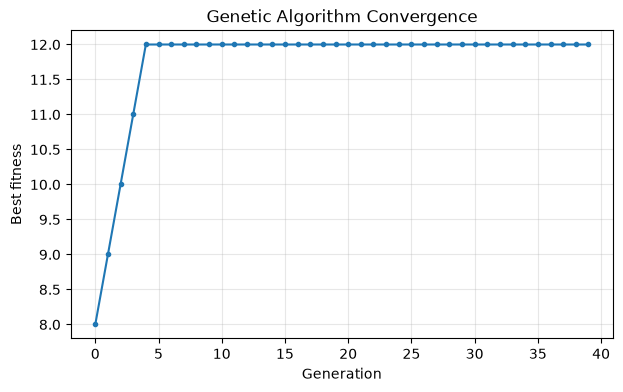

Initial best fitness: 8
Final best fitness: 12


In [17]:
plt.figure(figsize=(7, 4))
plt.plot(ga_history, marker="o", markersize=3)
plt.title("Genetic Algorithm Convergence")
plt.xlabel("Generation")
plt.ylabel("Best fitness")
plt.grid(True, alpha=0.3)
plt.show()
print(f"Initial best fitness: {ga_history[0]:.0f}")
print(f"Final best fitness: {ga_history[-1]:.0f}")

---
### Question 8:

To implement a simple Particle Swarm Optimization (PSO) algorithm for solving an optimization problem using Python.

In [18]:
# Minimize the Sphere function f(x) = sum(x^2).
def sphere(position):
    return np.sum(position ** 2, axis=-1)

particle_count, dimensions = 25, 2
positions = rng.uniform(-5, 5, size=(particle_count, dimensions))
velocities = np.zeros_like(positions)
personal_best = positions.copy()
personal_scores = sphere(personal_best)
global_best = personal_best[np.argmin(personal_scores)].copy()
pso_history = []

for _ in range(60):
    r1, r2 = rng.random((2, particle_count, dimensions))
    velocities = (0.7 * velocities + 1.4 * r1 * (personal_best - positions)
                  + 1.4 * r2 * (global_best - positions))
    positions = np.clip(positions + velocities, -5, 5)
    current_scores = sphere(positions)
    improved = current_scores < personal_scores
    personal_best[improved] = positions[improved]
    personal_scores[improved] = current_scores[improved]
    global_best = personal_best[np.argmin(personal_scores)].copy()
    pso_history.append(sphere(global_best))

print("Best position:", np.round(global_best, 5))
print(f"Minimum Sphere value: {sphere(global_best):.6f}")

Best position: [-1.e-05  1.e-05]
Minimum Sphere value: 0.000000


---
### Question 9:

To implement a simple Differential Evolution (DE) algorithm for solving an optimization problem using Python.

In [19]:
de_population = rng.uniform(-5, 5, size=(30, 2))
de_history = []

for _ in range(60):
    for index, target in enumerate(de_population):
        choices = [i for i in range(len(de_population)) if i != index]
        a, b, c = de_population[rng.choice(choices, size=3, replace=False)]
        mutant = np.clip(a + 0.8 * (b - c), -5, 5)
        mask = rng.random(2) < 0.8
        mask[rng.integers(0, 2)] = True
        trial = np.where(mask, mutant, target)
        if sphere(trial) <= sphere(target):
            de_population[index] = trial
    de_history.append(sphere(de_population).min())
de_best = de_population[np.argmin(sphere(de_population))]
print("Best vector:", np.round(de_best, 5))
print(f"Minimum Sphere value: {sphere(de_best):.6f}")

Best vector: [0. 0.]
Minimum Sphere value: 0.000000


---
### Question 10:

To design and implement a complete optimization system using a Genetic Algorithm in Python with the DEAP library by integrating population initialization, fitness evaluation, selection, crossover, mutation, and convergence analysis.


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


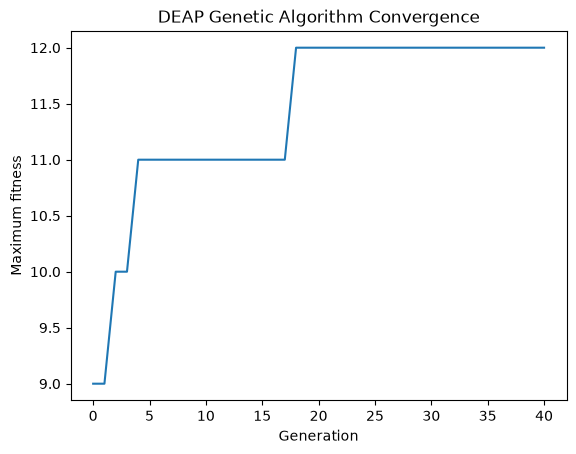

Best individual: [np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1)]
Best fitness: 12/12


In [20]:
# Install DEAP into the notebook's active kernel environment.
%pip install deap
from deap import algorithms, base, creator, tools
if not hasattr(creator, "FitnessMaxModule3"):
    creator.create("FitnessMaxModule3", base.Fitness, weights=(1.0,))
if not hasattr(creator, "IndividualModule3"):
    creator.create("IndividualModule3", list, fitness=creator.FitnessMaxModule3)

toolbox = base.Toolbox()
toolbox.register("gene", rng.integers, 0, 2)
toolbox.register("individual", tools.initRepeat, creator.IndividualModule3, toolbox.gene, n=12)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)
toolbox.register("evaluate", lambda individual: (sum(individual),))
toolbox.register("mate", tools.cxOnePoint)
toolbox.register("mutate", tools.mutFlipBit, indpb=1 / 12)
toolbox.register("select", tools.selTournament, tournsize=3)

deap_population = toolbox.population(n=30)
statistics = tools.Statistics(lambda individual: individual.fitness.values[0])
statistics.register("max", np.max)
statistics.register("avg", np.mean)
deap_population, logbook = algorithms.eaSimple(
    deap_population, toolbox, cxpb=0.7, mutpb=0.2, ngen=40,
    stats=statistics, halloffame=tools.HallOfFame(1), verbose=False
)
best = tools.selBest(deap_population, 1)[0]
deap_max_history = logbook.select("max")
plt.plot(deap_max_history)
plt.title("DEAP Genetic Algorithm Convergence")
plt.xlabel("Generation")
plt.ylabel("Maximum fitness")
plt.show()
print("Best individual:", best)
print(f"Best fitness: {best.fitness.values[0]:.0f}/{len(best)}")

---
### Conclusion

The notebook implemented the core evolutionary operators and combined them into Genetic Algorithm, PSO, and Differential Evolution optimizers. The convergence plots show how the population-based methods improve candidate solutions over successive iterations.